Transaction Dataset Exploration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

# Define dataset locations
DATA_DIR = Path("../data/raw")

ARTICLES_PATH = DATA_DIR / "articles.csv"
TRANSACTIONS_PATH = DATA_DIR / "transactions_train.csv"

print("Environment initialized!")

Environment initialized!


In [2]:
articles = pl.read_csv(ARTICLES_PATH)

print("Article dataset shape:", articles.shape)

print("\nColumn names:")
print(articles.columns)

print("\nFirst 5 records:")
display(articles.head())

Article dataset shape: (105542, 25)

Column names:
['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_no', 'graphical_appearance_name', 'colour_group_code', 'colour_group_name', 'perceived_colour_value_id', 'perceived_colour_value_name', 'perceived_colour_master_id', 'perceived_colour_master_name', 'department_no', 'department_name', 'index_code', 'index_name', 'index_group_no', 'index_group_name', 'section_no', 'section_name', 'garment_group_no', 'garment_group_name', 'detail_desc']

First 5 records:


article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
i64,i64,str,i64,str,str,i64,str,i64,str,i64,str,i64,str,i64,str,str,str,i64,str,i64,str,i64,str,str
108775015,108775,"""Strap top""",253,"""Vest top""","""Garment Upper body""",1010016,"""Solid""",9,"""Black""",4,"""Dark""",5,"""Black""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
108775044,108775,"""Strap top""",253,"""Vest top""","""Garment Upper body""",1010016,"""Solid""",10,"""White""",3,"""Light""",9,"""White""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
108775051,108775,"""Strap top (1)""",253,"""Vest top""","""Garment Upper body""",1010017,"""Stripe""",11,"""Off White""",1,"""Dusty Light""",9,"""White""",1676,"""Jersey Basic""","""A""","""Ladieswear""",1,"""Ladieswear""",16,"""Womens Everyday Basics""",1002,"""Jersey Basic""","""Jersey top with narrow shoulde…"
110065001,110065,"""OP T-shirt (Idro)""",306,"""Bra""","""Underwear""",1010016,"""Solid""",9,"""Black""",4,"""Dark""",5,"""Black""",1339,"""Clean Lingerie""","""B""","""Lingeries/Tights""",1,"""Ladieswear""",61,"""Womens Lingerie""",1017,"""Under-, Nightwear""","""Microfibre T-shirt bra with un…"
110065002,110065,"""OP T-shirt (Idro)""",306,"""Bra""","""Underwear""",1010016,"""Solid""",10,"""White""",3,"""Light""",9,"""White""",1339,"""Clean Lingerie""","""B""","""Lingeries/Tights""",1,"""Ladieswear""",61,"""Womens Lingerie""",1017,"""Under-, Nightwear""","""Microfibre T-shirt bra with un…"


In [3]:
# Inspect missing values
print(articles.null_count())

# Check unique article IDs
print(
    "Unique article IDs:",
    articles["article_id"].n_unique()
)

# Check unique product codes
print(
    "Unique product codes:",
    articles["product_code"].n_unique()
)

shape: (1, 25)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ article_i ┆ product_c ┆ prod_name ┆ product_t ┆ … ┆ section_n ┆ garment_g ┆ garment_g ┆ detail_d │
│ d         ┆ ode       ┆ ---       ┆ ype_no    ┆   ┆ ame       ┆ roup_no   ┆ roup_name ┆ esc      │
│ ---       ┆ ---       ┆ u32       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---      │
│ u32       ┆ u32       ┆           ┆ u32       ┆   ┆ u32       ┆ u32       ┆ u32       ┆ u32      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 0         ┆ 0         ┆ 0         ┆ 0         ┆ … ┆ 0         ┆ 0         ┆ 0         ┆ 416      │
└───────────┴───────────┴───────────┴───────────┴───┴───────────┴───────────┴───────────┴──────────┘
Unique article IDs: 105542
Unique product codes: 47224


In [4]:
#Loading and inspecting transaction data
from pathlib import Path

import polars as pl

DATA_DIR = Path("../data/raw")

TRANSACTIONS_PATH = DATA_DIR / "transactions_train.csv"

transactions = pl.scan_csv(
    TRANSACTIONS_PATH,
    infer_schema_length=10000
)

print("Transaction schema:")
print(transactions.collect_schema())

Transaction schema:
Schema([('t_dat', String), ('customer_id', String), ('article_id', Int64), ('price', Float64), ('sales_channel_id', Int64)])


In [5]:
sample = transactions.head(10).collect()

display(sample)

t_dat,customer_id,article_id,price,sales_channel_id
str,str,i64,f64,i64
"""2018-09-20""","""000058a12d5b43e67d225668fa1f8d…",663713001,0.050831,2
"""2018-09-20""","""000058a12d5b43e67d225668fa1f8d…",541518023,0.030492,2
"""2018-09-20""","""00007d2de826758b65a93dd24ce629…",505221004,0.015237,2
"""2018-09-20""","""00007d2de826758b65a93dd24ce629…",685687003,0.016932,2
"""2018-09-20""","""00007d2de826758b65a93dd24ce629…",685687004,0.016932,2
"""2018-09-20""","""00007d2de826758b65a93dd24ce629…",685687001,0.016932,2
"""2018-09-20""","""00007d2de826758b65a93dd24ce629…",505221001,0.020322,2
"""2018-09-20""","""00083cda041544b2fbb0e0d2905ad1…",688873012,0.030492,1
"""2018-09-20""","""00083cda041544b2fbb0e0d2905ad1…",501323011,0.053373,1


In [6]:
transaction_stats = transactions.select([
    pl.len().alias("total_transactions"),

    pl.col("article_id")
      .n_unique()
      .alias("unique_articles"),

    pl.col("customer_id")
      .n_unique()
      .alias("unique_customers"),

    pl.col("t_dat")
      .min()
      .alias("first_transaction"),

    pl.col("t_dat")
      .max()
      .alias("last_transaction"),

    pl.col("price")
      .min()
      .alias("minimum_price"),

    pl.col("price")
      .max()
      .alias("maximum_price")
]).collect(engine="streaming")

display(transaction_stats)

total_transactions,unique_articles,unique_customers,first_transaction,last_transaction,minimum_price,maximum_price
u32,u32,u32,str,str,f64,f64
31788324,104547,1362281,"""2018-09-20""","""2020-09-22""",0.000017,0.591525


In [7]:
article_ids = articles.select(
    "article_id"
).lazy()

transaction_article_ids = transactions.select(
    "article_id"
).unique()

unmatched_articles = (
    transaction_article_ids
    .join(
        article_ids,
        on="article_id",
        how="anti"
    )
    .select(pl.len().alias("unmatched_article_ids"))
    .collect(engine="streaming")
)

display(unmatched_articles)

unmatched_article_ids
u32
0


Weekly Sales Exploration

In [8]:
#Transaction date preprocessing
transactions_typed = transactions.with_columns(
    pl.col("t_dat")
    .str.to_date("%Y-%m-%d")
    .alias("transaction_date")
)

print(transactions_typed.collect_schema())

Schema([('t_dat', String), ('customer_id', String), ('article_id', Int64), ('price', Float64), ('sales_channel_id', Int64), ('transaction_date', Date)])


In [9]:
#Weekly sales aggregation
weekly_sales = (
    transactions_typed
    .with_columns(
        pl.col("transaction_date")
        .dt.truncate("1w")
        .alias("week_start")
    )
    .group_by(["article_id", "week_start"])
    .agg(
        pl.len().alias("units_sold")
    )
    .sort(["article_id", "week_start"])
)

print("Weekly sales schema:")
print(weekly_sales.collect_schema())

Weekly sales schema:
Schema([('article_id', Int64), ('week_start', Date), ('units_sold', UInt32)])


In [10]:
#First recorded sale per article
birth_dates = (
    transactions_typed
    .group_by("article_id")
    .agg(
        pl.col("transaction_date")
        .min()
        .alias("birth_date")
    )
    .sort("article_id")
)

display(birth_dates.head(10).collect())

article_id,birth_date
i64,date
108775015,2018-09-20
108775044,2018-09-20
108775051,2018-09-20
110065001,2018-09-20
110065002,2018-09-20
110065011,2018-09-20
111565001,2018-09-20
111565003,2018-10-31
111586001,2018-09-20


Outputs

In [11]:
#Output directory
Path("../data/interim").mkdir(
    parents=True,
    exist_ok=True
)

#Execute aggregation and save to Parquet
weekly_sales.sink_parquet(
    "../data/interim/weekly_sales_observed.parquet"
)

print("Weekly sales aggregation saved!")

Weekly sales aggregation saved!


In [12]:
birth_dates.sink_parquet(
    "../data/interim/article_birth_dates.parquet"
)

print("Article birth dates saved!")

Article birth dates saved!


In [13]:
#Reads new files
weekly_sales_result = pl.scan_parquet(
    "../data/interim/weekly_sales_observed.parquet"
)

birth_dates_result = pl.scan_parquet(
    "../data/interim/article_birth_dates.parquet"
)

print("Weekly sales:")
display(weekly_sales_result.head(10).collect())

print("Birth dates:")
display(birth_dates_result.head(10).collect())

Weekly sales:


article_id,week_start,units_sold
i64,date,u32
108775015,2018-09-17,115
108775015,2018-09-24,547
108775015,2018-10-01,315
108775015,2018-10-08,360
108775015,2018-10-15,259
108775015,2018-10-22,434
108775015,2018-10-29,373
108775015,2018-11-05,312
108775015,2018-11-12,244


Birth dates:


article_id,birth_date
i64,date
108775015,2018-09-20
108775044,2018-09-20
108775051,2018-09-20
110065001,2018-09-20
110065002,2018-09-20
110065011,2018-09-20
111565001,2018-09-20
111565003,2018-10-31
111586001,2018-09-20


In [14]:
#Integrity check
total_units = (
    weekly_sales_result
    .select(pl.col("units_sold").sum())
    .collect()
)

print("Original transactions:", 31_788_324)
print("Aggregated units:", total_units)

Original transactions: 31788324
Aggregated units: shape: (1, 1)
┌────────────┐
│ units_sold │
│ ---        │
│ u32        │
╞════════════╡
│ 31788324   │
└────────────┘


Complete Weekly Sales Panel

In [15]:
#Observation boundaries
date_boundaries = transactions_typed.select([
    pl.col("transaction_date")
      .min()
      .dt.truncate("1w")
      .alias("first_week"),

    pl.col("transaction_date")
      .max()
      .dt.truncate("1w")
      .alias("cutoff_week")
]).collect()

display(date_boundaries)

FIRST_WEEK = date_boundaries["first_week"][0]
CUTOFF_WEEK = date_boundaries["cutoff_week"][0]

print("First observed week:", FIRST_WEEK)
print("Final observed week:", CUTOFF_WEEK)

first_week,cutoff_week
date,date
2018-09-17,2020-09-21


First observed week: 2018-09-17
Final observed week: 2020-09-21


In [16]:
#Continuous weekly timelines
calendar = pl.DataFrame({
    "week_start": pl.date_range(
        start=FIRST_WEEK,
        end=CUTOFF_WEEK,
        interval="1w",
        eager=True
    )
})

display(calendar)
print("Total calendar weeks:", calendar.height)

week_start
date
2018-09-17
2018-09-24
2018-10-01
2018-10-08
2018-10-15
…
2020-08-24
2020-08-31
2020-09-07


Total calendar weeks: 106


In [17]:
#Timeline for every article
article_births = (
    birth_dates
    .with_columns(
        pl.col("birth_date")
        .dt.truncate("1w")
        .alias("birth_week")
    )
)

#Article-week combinations
article_calendar = (
    article_births
    .join(
        calendar.lazy(),
        how="cross"
    )
    .filter(
        pl.col("week_start") >= pl.col("birth_week")
    )
)

print("Article calendar created.")

Article calendar created.


In [18]:
#Attach observed sales to complete calendar and fill missing sales with zero
weekly_panel = (
    article_calendar
    .join(
        weekly_sales,
        on=["article_id", "week_start"],
        how="left"
    )
    .with_columns(
        pl.col("units_sold")
        .fill_null(0)
        .cast(pl.UInt32)
    )
)

In [19]:
#Calculate product age
weekly_panel = (
    weekly_panel
    .with_columns(
        (
            (
                pl.col("week_start") -
                pl.col("birth_week")
            ).dt.total_days() // 7
        )
        .cast(pl.Int32)
        .alias("age_week")
    )
    .select([
        "article_id",
        "birth_date",
        "birth_week",
        "week_start",
        "age_week",
        "units_sold"
    ])
)

In [20]:
#Save the completed panel
Path("../data/processed").mkdir(
    parents=True,
    exist_ok=True
)

weekly_panel.sink_parquet(
    "../data/processed/weekly_panel.parquet"
)

print("Complete weekly panel saved!")

Complete weekly panel saved!


Validate New Dataset

In [21]:
#Inspect
panel = pl.scan_parquet(
    "../data/processed/weekly_panel.parquet"
)

print(panel.collect_schema())

display(
    panel.head(20).collect()
)

Schema([('article_id', Int64), ('birth_date', Date), ('birth_week', Date), ('week_start', Date), ('age_week', Int32), ('units_sold', UInt32)])


article_id,birth_date,birth_week,week_start,age_week,units_sold
i64,date,date,date,i32,u32
637346002,2018-09-23,2018-09-17,2018-10-15,4,2
589004004,2018-09-20,2018-09-17,2018-10-15,4,0
368038004,2018-09-21,2018-09-17,2018-10-15,4,13
333323018,2018-09-20,2018-09-17,2018-10-15,4,10
528070005,2018-09-20,2018-09-17,2018-10-15,4,6
…,…,…,…,…,…
653122001,2018-09-23,2018-09-17,2018-10-15,4,7
560783011,2018-09-23,2018-09-17,2018-10-15,4,2
351933038,2018-09-20,2018-09-17,2018-10-15,4,5


In [22]:
#Count generated records
panel_stats = panel.select([
    pl.len().alias("total_panel_rows"),

    pl.col("article_id")
      .n_unique()
      .alias("unique_articles"),

    pl.col("units_sold")
      .sum()
      .alias("total_units_sold"),

    (pl.col("units_sold") == 0)
      .sum()
      .alias("zero_sales_weeks"),

    pl.col("age_week")
      .max()
      .alias("maximum_product_age")
]).collect(engine="streaming")

display(panel_stats)

total_panel_rows,unique_articles,total_units_sold,zero_sales_weeks,maximum_product_age
u32,u32,u32,u32,i32
7371317,104547,31788324,5160418,105


In [23]:
#Verify product timelines contunuity
continuity_check = (
    panel
    .group_by("article_id")
    .agg([
        pl.col("age_week").min().alias("min_age"),
        pl.col("age_week").max().alias("max_age"),
        pl.col("age_week").n_unique().alias("unique_weeks"),
        pl.len().alias("total_weeks")
    ])
    .with_columns(
        (
            (pl.col("min_age") == 0) &
            (pl.col("max_age") + 1 == pl.col("unique_weeks")) &
            (pl.col("unique_weeks") == pl.col("total_weeks"))
        ).alias("is_continuous")
    )
)

continuity_summary = continuity_check.select([
    pl.len().alias("articles_checked"),

    pl.col("is_continuous")
      .sum()
      .alias("continuous_articles"),

    (~pl.col("is_continuous"))
      .sum()
      .alias("non_continuous_articles")
]).collect()

display(continuity_summary)


articles_checked,continuous_articles,non_continuous_articles
u32,u32,u32
104547,104547,0


Sales History Analyzation

In [24]:
#Summarization of each article's sales history
article_summary = (
    panel
    .group_by("article_id")
    .agg([
        pl.col("birth_date").first().alias("birth_date"),

        pl.col("birth_week").first().alias("birth_week"),

        pl.col("week_start").min().alias("first_observed_week"),

        pl.col("week_start").max().alias("last_observed_week"),

        pl.col("age_week").max().alias("observed_lifetime_weeks"),

        pl.len().alias("total_observed_weeks"),

        pl.col("units_sold")
        .sum()
        .alias("total_units_sold"),

        (pl.col("units_sold") > 0)
        .sum()
        .alias("weeks_with_sales"),

        (pl.col("units_sold") == 0)
        .sum()
        .alias("zero_sales_weeks"),

        pl.col("week_start")
        .filter(pl.col("units_sold") > 0)
        .max()
        .alias("last_positive_sales_week"),

        pl.col("units_sold")
        .max()
        .alias("maximum_weekly_sales"),

        pl.col("units_sold")
        .mean()
        .alias("average_weekly_sales")
    ])
    .sort("article_id")
)

article_summary_df = article_summary.collect()

display(article_summary_df.head(10))

article_id,birth_date,birth_week,first_observed_week,last_observed_week,observed_lifetime_weeks,total_observed_weeks,total_units_sold,weeks_with_sales,zero_sales_weeks,last_positive_sales_week,maximum_weekly_sales,average_weekly_sales
i64,date,date,date,date,i32,u32,u32,u32,u32,date,u32,f64
108775015,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,10841,77,29,2020-07-20,680,102.273585
108775044,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,7250,104,2,2020-09-14,312,68.396226
108775051,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,215,16,90,2019-06-24,45,2.028302
110065001,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,1044,86,20,2020-07-27,64,9.849057
110065002,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,539,77,29,2020-08-03,46,5.084906
110065011,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,1090,81,25,2020-08-31,76,10.283019
111565001,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,4911,106,0,2020-09-21,157,46.330189
111565003,2018-10-31,2018-10-29,2018-10-29,2020-09-21,99,100,46,14,86,2019-02-04,7,0.46
111586001,2018-09-20,2018-09-17,2018-09-17,2020-09-21,105,106,14191,100,6,2020-09-21,475,133.877358


In [25]:
#Article distribution summary
article_distribution = article_summary_df.select([
    pl.len().alias("total_articles"),

    pl.col("observed_lifetime_weeks")
    .mean().alias("mean_observed_lifetime"),

    pl.col("observed_lifetime_weeks")
    .median().alias("median_observed_lifetime"),

    pl.col("observed_lifetime_weeks")
    .quantile(0.25).alias("lifetime_q25"),

    pl.col("observed_lifetime_weeks")
    .quantile(0.75).alias("lifetime_q75"),

    pl.col("total_units_sold")
    .mean().alias("mean_total_sales"),

    pl.col("total_units_sold")
    .median().alias("median_total_sales"),

    pl.col("weeks_with_sales")
    .mean().alias("mean_weeks_with_sales"),

    pl.col("zero_sales_weeks")
    .mean().alias("mean_zero_sales_weeks"),

    pl.col("average_weekly_sales")
    .mean().alias("mean_weekly_sales")
])

display(article_distribution)

total_articles,mean_observed_lifetime,median_observed_lifetime,lifetime_q25,lifetime_q75,mean_total_sales,median_total_sales,mean_weeks_with_sales,mean_zero_sales_weeks,mean_weekly_sales
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
104547,69.507207,79.0,40.0,103.0,304.057735,65.0,21.147417,49.35979,6.449111


In [26]:
#Sales activity by product age
age_profile = (
    panel
    .group_by("age_week")
    .agg([
        pl.len().alias("article_week_observations"),

        pl.col("units_sold")
        .mean()
        .alias("mean_units_sold"),

        pl.col("units_sold")
        .median()
        .alias("median_units_sold"),

        (pl.col("units_sold") == 0)
        .mean()
        .alias("zero_sales_fraction"),

        (pl.col("units_sold") > 0)
        .sum()
        .alias("articles_with_sales")
    ])
    .sort("age_week")
    .collect()
)

display(age_profile.head(30))

age_week,article_week_observations,mean_units_sold,median_units_sold,zero_sales_fraction,articles_with_sales
i32,u32,f64,f64,f64,u32
0,104547,10.816169,2.0,0.0,104547
1,104367,18.072897,4.0,0.247444,78542
2,103629,16.48968,3.0,0.266595,76002
3,102558,16.427446,3.0,0.271602,74703
4,101743,15.106474,3.0,0.288383,72402
…,…,…,…,…,…
25,88893,3.690583,0.0,0.64329,31709
26,87961,3.354725,0.0,0.658064,30077
27,87299,3.272466,0.0,0.67042,28772


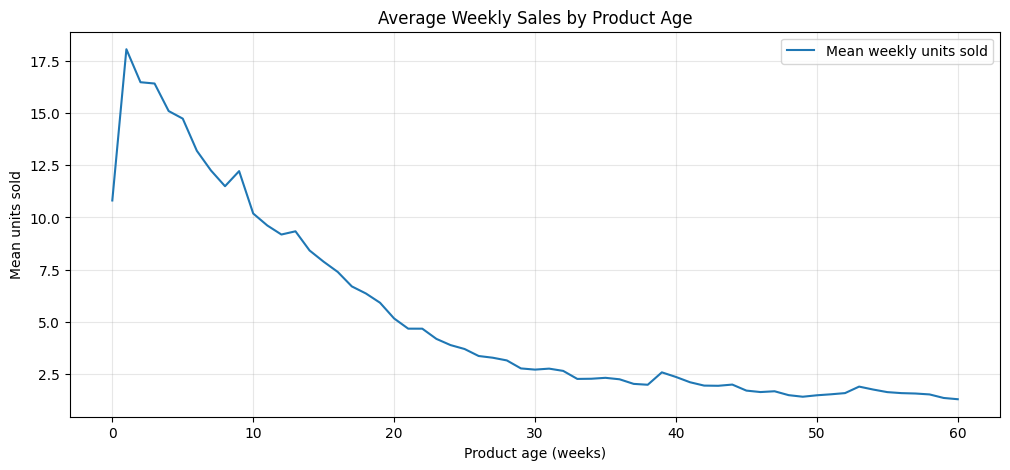

In [27]:
#Visualization of sales activity by product age

age_plot = age_profile.filter(
    pl.col("age_week") <= 60
)

plt.figure(figsize=(12, 5))

plt.plot(
    age_plot["age_week"],
    age_plot["mean_units_sold"],
    label="Mean weekly units sold"
)

plt.xlabel("Product age (weeks)")
plt.ylabel("Mean units sold")
plt.title("Average Weekly Sales by Product Age")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

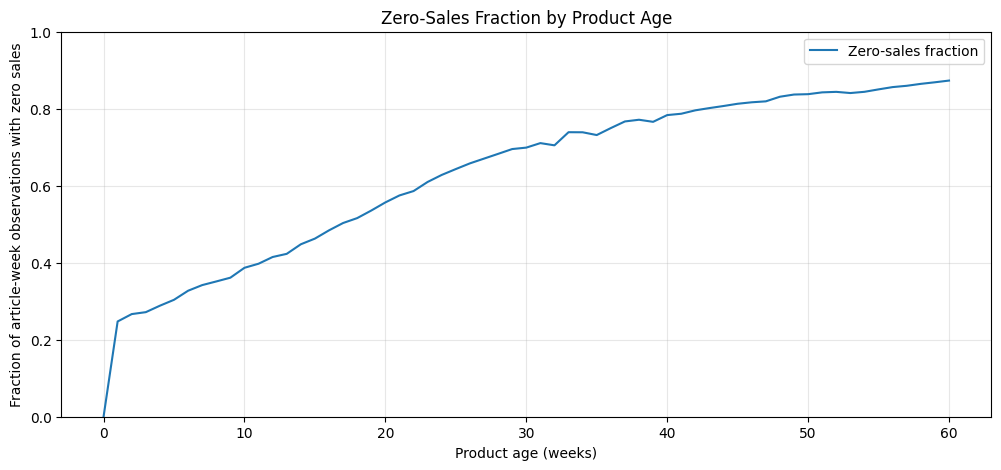

In [28]:
#Visualization for zero-sales behaviour
plt.figure(figsize=(12, 5))

plt.plot(
    age_plot["age_week"],
    age_plot["zero_sales_fraction"],
    label="Zero-sales fraction"
)

plt.xlabel("Product age (weeks)")
plt.ylabel("Fraction of article-week observations with zero sales")
plt.title("Zero-Sales Fraction by Product Age")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Detailed Observation Boundaries

In [29]:
from datetime import timedelta

#Get final transaction date
LAST_TRANSACTION_DATE = (
    transactions_typed
    .select(pl.col("transaction_date").max())
    .collect()
    .item()
)

#Find the Monday of the final calendar week
CUTOFF_WEEK = (
    LAST_TRANSACTION_DATE
    - timedelta(days=LAST_TRANSACTION_DATE.weekday())
)

#Determine whether final calendar week is complete
WEEK_END = CUTOFF_WEEK + timedelta(days=6)

if LAST_TRANSACTION_DATE >= WEEK_END:
    LAST_COMPLETE_WEEK = CUTOFF_WEEK
else:
    LAST_COMPLETE_WEEK = CUTOFF_WEEK - timedelta(days=7)

print("Last transaction date:", LAST_TRANSACTION_DATE)
print("Final calendar week:", CUTOFF_WEEK)
print("Last complete week:", LAST_COMPLETE_WEEK)

Last transaction date: 2020-09-22
Final calendar week: 2020-09-21
Last complete week: 2020-09-14


In [30]:
#Calculate complete zero-sales weeks, after article's last positive-sales week

lifecycle_base = (
    article_summary_df
    .lazy()
    .with_columns(
        pl.when(
            pl.col("last_positive_sales_week")
            <= pl.lit(LAST_COMPLETE_WEEK)
        )
        .then(
            (
                (
                    pl.lit(LAST_COMPLETE_WEEK)
                    - pl.col("last_positive_sales_week")
                ).dt.total_days() // 7
            ).cast(pl.Int32)
        )
        .otherwise(pl.lit(0))
        .alias("complete_zero_weeks_after_last_sale")
    )
)

display(
    lifecycle_base
    .select([
        "article_id",
        "birth_date",
        "last_positive_sales_week",
        "complete_zero_weeks_after_last_sale"
    ])
    .head(15)
    .collect()
)

article_id,birth_date,last_positive_sales_week,complete_zero_weeks_after_last_sale
i64,date,date,i32
108775015,2018-09-20,2020-07-20,8
108775044,2018-09-20,2020-09-14,0
108775051,2018-09-20,2019-06-24,64
110065001,2018-09-20,2020-07-27,7
110065002,2018-09-20,2020-08-03,6
…,…,…,…
111609001,2018-09-20,2020-09-21,0
112679048,2018-10-15,2019-06-24,64
112679052,2018-11-22,2018-12-24,90


Default Lifecycle Label

In [31]:
#Lifecycle: w = 4
lifecycle_w4 = (
    lifecycle_base
    .with_columns([
        (
            pl.col("complete_zero_weeks_after_last_sale") >= 4
        ).alias("event_observed_w4"),

        pl.when(
            pl.col("complete_zero_weeks_after_last_sale") >= 4
        )
        .then(
            pl.col("last_positive_sales_week")
            + pl.duration(days=7)
        )
        .otherwise(None)
        .alias("death_week_w4"),

        pl.lit(LAST_TRANSACTION_DATE)
        .alias("censor_date")
    ])
    .with_columns([
        pl.when(pl.col("event_observed_w4"))
        .then(pl.lit("death_observed"))
        .otherwise(pl.lit("right_censored"))
        .alias("lifecycle_status_w4"),

        pl.when(pl.col("event_observed_w4"))
        .then(
            (
                (
                    pl.col("last_positive_sales_week")
                    + pl.duration(days=7)
                    - pl.col("birth_week")
                ).dt.total_days() // 7
            ).cast(pl.Int32)
        )
        .otherwise(None)
        .alias("death_age_week_w4"),

        (
            (
                pl.lit(CUTOFF_WEEK)
                - pl.col("birth_week")
            ).dt.total_days() // 7
        ).cast(pl.Int32).alias("censor_age_week")
    ])
)

lifecycle_w4_df = lifecycle_w4.collect()

display(
    lifecycle_w4_df.select([
        "article_id",
        "birth_date",
        "last_positive_sales_week",
        "complete_zero_weeks_after_last_sale",
        "lifecycle_status_w4",
        "event_observed_w4",
        "death_week_w4",
        "death_age_week_w4",
        "censor_date",
        "censor_age_week"
    ]).head(20)
)

article_id,birth_date,last_positive_sales_week,complete_zero_weeks_after_last_sale,lifecycle_status_w4,event_observed_w4,death_week_w4,death_age_week_w4,censor_date,censor_age_week
i64,date,date,i32,str,bool,date,i32,date,i32
108775015,2018-09-20,2020-07-20,8,"""death_observed""",true,2020-07-27,97,2020-09-22,105
108775044,2018-09-20,2020-09-14,0,"""right_censored""",false,null,null,2020-09-22,105
108775051,2018-09-20,2019-06-24,64,"""death_observed""",true,2019-07-01,41,2020-09-22,105
110065001,2018-09-20,2020-07-27,7,"""death_observed""",true,2020-08-03,98,2020-09-22,105
110065002,2018-09-20,2020-08-03,6,"""death_observed""",true,2020-08-10,99,2020-09-22,105
…,…,…,…,…,…,…,…,…,…
116379047,2018-09-20,2020-06-08,14,"""death_observed""",true,2020-06-15,91,2020-09-22,105
118458003,2018-09-25,2019-04-29,72,"""death_observed""",true,2019-05-06,32,2020-09-22,104
118458004,2018-09-20,2019-11-11,44,"""death_observed""",true,2019-11-18,61,2020-09-22,105


Default Sensitivity Label

In [32]:
#Sensitivity: w = 8
lifecycle_labels = (
    lifecycle_w4
    .with_columns([
        (
            pl.col("complete_zero_weeks_after_last_sale") >= 8
        ).alias("event_observed_w8"),

        pl.when(
            pl.col("complete_zero_weeks_after_last_sale") >= 8
        )
        .then(
            pl.col("last_positive_sales_week")
            + pl.duration(days=7)
        )
        .otherwise(None)
        .alias("death_week_w8")
    ])
    .with_columns([
        pl.when(pl.col("event_observed_w8"))
        .then(pl.lit("death_observed"))
        .otherwise(pl.lit("right_censored"))
        .alias("lifecycle_status_w8"),

        pl.when(pl.col("event_observed_w8"))
        .then(
            (
                (
                    pl.col("last_positive_sales_week")
                    + pl.duration(days=7)
                    - pl.col("birth_week")
                ).dt.total_days() // 7
            ).cast(pl.Int32)
        )
        .otherwise(None)
        .alias("death_age_week_w8")
    ])
)

lifecycle_labels_df = lifecycle_labels.collect()

display(
    lifecycle_labels_df.select([
        "article_id",
        "lifecycle_status_w4",
        "lifecycle_status_w8",
        "death_age_week_w4",
        "death_age_week_w8"
    ]).head(20)
)

article_id,lifecycle_status_w4,lifecycle_status_w8,death_age_week_w4,death_age_week_w8
i64,str,str,i32,i32
108775015,"""death_observed""","""death_observed""",97,97
108775044,"""right_censored""","""right_censored""",null,null
108775051,"""death_observed""","""death_observed""",41,41
110065001,"""death_observed""","""right_censored""",98,null
110065002,"""death_observed""","""right_censored""",99,null
…,…,…,…,…
116379047,"""death_observed""","""death_observed""",91,91
118458003,"""death_observed""","""death_observed""",32,32
118458004,"""death_observed""","""death_observed""",61,61


Lifecycle Outcome Summarization

In [33]:
lifecycle_summary = lifecycle_labels_df.select([
    pl.len().alias("total_articles"),

    pl.col("event_observed_w4")
    .sum()
    .alias("deaths_confirmed_w4"),

    (~pl.col("event_observed_w4"))
    .sum()
    .alias("right_censored_w4"),

    pl.col("event_observed_w8")
    .sum()
    .alias("deaths_confirmed_w8"),

    (~pl.col("event_observed_w8"))
    .sum()
    .alias("right_censored_w8")
])

display(lifecycle_summary)

total_articles,deaths_confirmed_w4,right_censored_w4,deaths_confirmed_w8,right_censored_w8
u32,u32,u32,u32,u32
104547,75658,28889,68533,36014


Clean Label Table

In [34]:
from pathlib import Path

lifecycle_final = (
    lifecycle_labels_df
    .rename({
        "censor_age_week": "observation_end_age_week"
    })
    .with_columns([
        pl.when(pl.col("event_observed_w4"))
        .then(None)
        .otherwise(pl.col("observation_end_age_week"))
        .cast(pl.Int32)
        .alias("censor_age_week_w4"),

        pl.when(pl.col("event_observed_w8"))
        .then(None)
        .otherwise(pl.col("observation_end_age_week"))
        .cast(pl.Int32)
        .alias("censor_age_week_w8")
    ])
)

lifecycle_final = lifecycle_final.select([
    "article_id",
    "birth_date",
    "birth_week",
    "last_positive_sales_week",
    "complete_zero_weeks_after_last_sale",

    "lifecycle_status_w4",
    "event_observed_w4",
    "death_week_w4",
    "death_age_week_w4",
    "censor_age_week_w4",

    "lifecycle_status_w8",
    "event_observed_w8",
    "death_week_w8",
    "death_age_week_w8",
    "censor_age_week_w8",

    "censor_date",
    "observation_end_age_week"
])

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "article_lifecycle_labels.parquet"

lifecycle_final.write_parquet(output_path)

print("Saved:", output_path)
print("Rows:", lifecycle_final.height)
print("Columns:", lifecycle_final.columns)

Saved: ..\data\processed\article_lifecycle_labels.parquet
Rows: 104547
Columns: ['article_id', 'birth_date', 'birth_week', 'last_positive_sales_week', 'complete_zero_weeks_after_last_sale', 'lifecycle_status_w4', 'event_observed_w4', 'death_week_w4', 'death_age_week_w4', 'censor_age_week_w4', 'lifecycle_status_w8', 'event_observed_w8', 'death_week_w8', 'death_age_week_w8', 'censor_age_week_w8', 'censor_date', 'observation_end_age_week']


Saved Dataset Inspection

In [35]:
saved_lifecycle = pl.read_parquet(
    "../data/processed/article_lifecycle_labels.parquet"
)

display(saved_lifecycle.head(10))

display(
    saved_lifecycle.select([
        pl.len().alias("total_articles"),

        pl.col("event_observed_w4").sum()
        .alias("deaths_w4"),

        pl.col("event_observed_w8").sum()
        .alias("deaths_w8"),

        pl.col("censor_age_week_w4").is_not_null()
        .sum().alias("censored_w4"),

        pl.col("censor_age_week_w8").is_not_null()
        .sum().alias("censored_w8")
    ])
)

article_id,birth_date,birth_week,last_positive_sales_week,complete_zero_weeks_after_last_sale,lifecycle_status_w4,event_observed_w4,death_week_w4,death_age_week_w4,censor_age_week_w4,lifecycle_status_w8,event_observed_w8,death_week_w8,death_age_week_w8,censor_age_week_w8,censor_date,observation_end_age_week
i64,date,date,date,i32,str,bool,date,i32,i32,str,bool,date,i32,i32,date,i32
108775015,2018-09-20,2018-09-17,2020-07-20,8,"""death_observed""",true,2020-07-27,97,null,"""death_observed""",true,2020-07-27,97,null,2020-09-22,105
108775044,2018-09-20,2018-09-17,2020-09-14,0,"""right_censored""",false,null,null,105,"""right_censored""",false,null,null,105,2020-09-22,105
108775051,2018-09-20,2018-09-17,2019-06-24,64,"""death_observed""",true,2019-07-01,41,null,"""death_observed""",true,2019-07-01,41,null,2020-09-22,105
110065001,2018-09-20,2018-09-17,2020-07-27,7,"""death_observed""",true,2020-08-03,98,null,"""right_censored""",false,null,null,105,2020-09-22,105
110065002,2018-09-20,2018-09-17,2020-08-03,6,"""death_observed""",true,2020-08-10,99,null,"""right_censored""",false,null,null,105,2020-09-22,105
110065011,2018-09-20,2018-09-17,2020-08-31,2,"""right_censored""",false,null,null,105,"""right_censored""",false,null,null,105,2020-09-22,105
111565001,2018-09-20,2018-09-17,2020-09-21,0,"""right_censored""",false,null,null,105,"""right_censored""",false,null,null,105,2020-09-22,105
111565003,2018-10-31,2018-10-29,2019-02-04,84,"""death_observed""",true,2019-02-11,15,null,"""death_observed""",true,2019-02-11,15,null,2020-09-22,99
111586001,2018-09-20,2018-09-17,2020-09-21,0,"""right_censored""",false,null,null,105,"""right_censored""",false,null,null,105,2020-09-22,105


total_articles,deaths_w4,deaths_w8,censored_w4,censored_w8
u32,u32,u32,u32,u32
104547,75658,68533,28889,36014


Determine k for Mode B (first k week of sales)(mode A doesnt use k)

In [36]:
K_CANDIDATES = [1, 2, 4, 6, 8, 12]

k_results = []

for k in K_CANDIDATES:

    if k == 1:
        eligible = article_summary_df.height

    else:
        required_last_week = (
            pl.col("birth_week")
            + pl.duration(days=7 * (k - 1))
        )

        eligible = (
            article_summary_df
            .filter(required_last_week <= LAST_COMPLETE_WEEK)
            .height
        )

    k_results.append({
        "k": k,
        "eligible_articles": eligible,
        "coverage_fraction": eligible / article_summary_df.height
    })

k_coverage_results = pl.DataFrame(k_results)

display(
    k_coverage_results.with_columns(
        (pl.col("coverage_fraction") * 100)
        .round(2)
        .alias("coverage_percentage")
    )
)

k,eligible_articles,coverage_fraction,coverage_percentage
i64,i64,f64,f64
1,104547,1.0,100.0
2,103629,0.991219,99.12
4,101743,0.97318,97.32
6,99850,0.955073,95.51
8,98518,0.942332,94.23
12,96191,0.920074,92.01


Image Dataset Inspection and Mapping

In [37]:
from pathlib import Path

RAW_DIR = Path("../data/raw")

print("Raw directory exists:", RAW_DIR.exists())

if RAW_DIR.exists():
    for item in RAW_DIR.iterdir():
        if item.is_dir():
            print(f"[DIR]  {item.name}")
        else:
            print(f"[FILE] {item.name}")

Raw directory exists: True
[FILE] articles.csv
[FILE] customers.csv
[DIR]  images
[FILE] sample_submission.csv
[FILE] transactions_train.csv


In [38]:
from collections import Counter
from pathlib import Path

IMAGE_DIR = RAW_DIR / "images"

print("Image directory exists:", IMAGE_DIR.exists())

subfolders = sorted(
    [p for p in IMAGE_DIR.iterdir() if p.is_dir()]
)

print("\nNumber of image subfolders:", len(subfolders))
print("\nFirst 15 subfolders:")

for folder in subfolders[:15]:
    print(folder.name)

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

image_files = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("\nTotal image files:", len(image_files))

extension_counts = Counter(
    p.suffix.lower() for p in image_files
)

print("\nImage formats:")
for extension, count in extension_counts.items():
    print(extension, count)

print("\nSample image paths:")

for path in image_files[:10]:
    print(path)

Image directory exists: True

Number of image subfolders: 86

First 15 subfolders:
010
011
012
013
014
015
016
017
018
019
020
021
022
023
024

Total image files: 105100

Image formats:
.jpg 105100

Sample image paths:
..\data\raw\images\010\0108775015.jpg
..\data\raw\images\010\0108775044.jpg
..\data\raw\images\010\0108775051.jpg
..\data\raw\images\011\0110065001.jpg
..\data\raw\images\011\0110065002.jpg
..\data\raw\images\011\0110065011.jpg
..\data\raw\images\011\0111565001.jpg
..\data\raw\images\011\0111565003.jpg
..\data\raw\images\011\0111586001.jpg
..\data\raw\images\011\0111593001.jpg


In [39]:
#Check if image filenames match article IDs
articles = pl.read_csv(
    RAW_DIR / "articles.csv",
    infer_schema_length=10000
)

print("Article records:", articles.height)

image_samples = pl.DataFrame({
    "image_path": [str(p) for p in image_files[:15]],
    "image_filename": [p.stem for p in image_files[:15]]
})

display(image_samples)

display(
    articles.select("article_id").head(15)
)

Article records: 105542


image_path,image_filename
str,str
"""..\data\raw\images\010\0108775…","""0108775015"""
"""..\data\raw\images\010\0108775…","""0108775044"""
"""..\data\raw\images\010\0108775…","""0108775051"""
"""..\data\raw\images\011\0110065…","""0110065001"""
"""..\data\raw\images\011\0110065…","""0110065002"""
…,…
"""..\data\raw\images\011\0111609…","""0111609001"""
"""..\data\raw\images\011\0112679…","""0112679048"""
"""..\data\raw\images\011\0112679…","""0112679052"""


article_id
i64
108775015
108775044
108775051
110065001
110065002
…
111609001
112679048
112679052


In [40]:
#Build image index from the extracted image directory
image_index = pl.DataFrame({
    "image_filename": [p.stem for p in image_files],
    "image_path": [str(p) for p in image_files]
})

#Convert zero-padded filenames into article IDs
image_index = image_index.with_columns(
    pl.col("image_filename")
    .cast(pl.Int64)
    .alias("article_id")
)

#Check duplicate article IDs
duplicate_images = (
    image_index
    .group_by("article_id")
    .len()
    .filter(pl.col("len") > 1)
)

print("Total image files:", image_index.height)
print("Unique image IDs:", image_index["article_id"].n_unique())
print("Duplicate image IDs:", duplicate_images.height)

#Join image paths with article metadata
article_image_mapping = articles.select(
    "article_id"
).join(
    image_index.select(["article_id", "image_path"]),
    on="article_id",
    how="left"
)

#Check image availability
image_mapping_summary = article_image_mapping.select([
    pl.len().alias("total_articles"),

    pl.col("image_path")
    .is_not_null()
    .sum()
    .alias("articles_with_images"),

    pl.col("image_path")
    .is_null()
    .sum()
    .alias("articles_without_images")
])

display(image_mapping_summary)

Total image files: 105100
Unique image IDs: 105100
Duplicate image IDs: 0


total_articles,articles_with_images,articles_without_images
u32,u32,u32
105542,105100,442


In [41]:
#Articles without images
missing_images = (
    article_image_mapping
    .filter(pl.col("image_path").is_null())
)

print("Articles without images:", missing_images.height)

display(missing_images.head(20))

#Images not matching article metadata
unmatched_images = (
    image_index
    .join(
        articles.select("article_id"),
        on="article_id",
        how="anti"
    )
)

print("Images without article metadata:", unmatched_images.height)

display(unmatched_images.head(20))

Articles without images: 442


article_id,image_path
i64,str
174057028,null
179208001,null
212042043,null
212042066,null
212629004,null
…,…
369423002,null
369423004,null
388916001,null


Images without article metadata: 0


image_filename,image_path,article_id
str,str,i64


In [42]:
from collections import Counter

from PIL import Image

dimension_counts = Counter()
corrupted_images = []
image_modes = Counter()

for path in image_files:
    try:
        with Image.open(path) as img:
            dimension_counts[img.size] += 1
            image_modes[img.mode] += 1

            img.verify()

    except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as e:
        corrupted_images.append({
            "image_path": str(path),
            "error": str(e)
        })

print("Image dimension distribution:")
for dimensions, count in dimension_counts.most_common(15):
    print(dimensions, count)

print("\nImage color modes:")
for mode, count in image_modes.items():
    print(mode, count)

print("\nCorrupted images:", len(corrupted_images))

Image dimension distribution:
(1166, 1750) 93377
(1167, 1750) 217
(1166, 1749) 51
(1352, 1750) 21
(1300, 1750) 20
(1378, 1750) 20
(1371, 1750) 20
(1306, 1750) 19
(1275, 1750) 19
(1244, 1750) 19
(1279, 1750) 19
(1283, 1750) 19
(1351, 1750) 18
(1347, 1750) 18
(1296, 1750) 18

Image color modes:
RGB 105099
L 1

Corrupted images: 0


In [43]:
from pathlib import Path

INTERIM_DIR = Path("../data/interim")
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

#Save complete mapping, including articles with missing images
article_image_mapping.write_parquet(
    INTERIM_DIR / "article_image_mapping.parquet"
)

#Save separate missing image report
missing_images.write_parquet(
    INTERIM_DIR / "articles_without_images.parquet"
)

print("Saved article-image mapping.")
print("Saved missing-image report.")

Saved article-image mapping.
Saved missing-image report.


In [44]:
from pathlib import Path

import polars as pl

PROCESSED_DIR = Path("../data/processed")
INTERIM_DIR = Path("../data/interim")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

#Save corrupted image report
corrupted_report = pl.DataFrame(corrupted_images)

if corrupted_images:
    corrupted_report.write_parquet(
        PROCESSED_DIR / "corrupted_images.parquet"
    )
else:
    #Preserve valid typed empty report
    corrupted_report = pl.DataFrame(
        schema={
            "image_path": pl.String,
            "error": pl.String
        }
    )
    corrupted_report.write_parquet(
        PROCESSED_DIR / "corrupted_images.parquet"
    )

#Save image dimension distribution
dimension_summary = pl.DataFrame([
    {
        "width": width,
        "height": height,
        "image_count": count
    }
    for (width, height), count in dimension_counts.items()
])

dimension_summary.write_parquet(
    PROCESSED_DIR / "image_dimension_summary.parquet"
)

#Save image color mode distribution
mode_summary = pl.DataFrame([
    {
        "color_mode": mode,
        "image_count": count
    }
    for mode, count in image_modes.items()
])

mode_summary.write_parquet(
    PROCESSED_DIR / "image_color_mode_summary.parquet"
)

print("Saved image inspection reports.")

Saved image inspection reports.


In [45]:
print("Mapping rows:", article_image_mapping.height)
print("Unique article IDs:", article_image_mapping["article_id"].n_unique())
print("Articles with images:", article_image_mapping["image_path"].is_not_null().sum())
print("Articles without images:", article_image_mapping["image_path"].is_null().sum())

Mapping rows: 105542
Unique article IDs: 105542
Articles with images: 105100
Articles without images: 442


Forecasting dataset inspection

In [ ]:
from pathlib import Path

import polars as pl

#Support execution whether kernel starts in repository root or notebooks directory
candidate_dirs = [
    Path("../data/processed"),
    Path("data/processed"),
]

PROCESSED_DIR = next(
    (path for path in candidate_dirs
     if (path / "forecasting_dataset.parquet").exists()),
    None,
)

if PROCESSED_DIR is None:
    raise FileNotFoundError(
        "Could not locate data/processed/forecasting_dataset.parquet"
    )

forecasting_dataset = pl.read_parquet(
    PROCESSED_DIR / "forecasting_dataset.parquet"
)

forecasting_eligibility_summary = pl.read_parquet(
    PROCESSED_DIR / "forecasting_eligibility_summary.parquet"
)

print("Dataset shape:", forecasting_dataset.shape)
print("Unique articles:", forecasting_dataset["article_id"].n_unique())
print("\nDataset schema:")
print(forecasting_dataset.schema)

print("\nEligibility summary:")
display(forecasting_eligibility_summary)


Dataset shape: (105542, 23)
Unique articles: 105542

Dataset schema:
Schema([('article_id', Int64), ('product_code', Int64), ('split', String), ('birth_date', Date), ('birth_week', Date), ('has_observed_sales', Boolean), ('mode_b_input_weeks_available', UInt32), ('target_weeks_available', UInt32), ('target_end_week_start', Date), ('mode_b_input_complete', Boolean), ('target_window_complete', Boolean), ('forecast_eligible', Boolean), ('ineligibility_reason', String), ('mode_b_input_units_age_0', UInt32), ('mode_b_input_units_age_1', UInt32), ('mode_b_input_units_age_2', UInt32), ('mode_b_input_units_age_3', UInt32), ('target_units_age_4', UInt32), ('target_units_age_5', UInt32), ('target_units_age_6', UInt32), ('target_units_age_7', UInt32), ('target_units_age_8', UInt32), ('target_units_age_9', UInt32)])

Eligibility summary:


split,total_articles,articles_with_observed_sales,eligible_articles,ineligible_articles,eligibility_coverage_pct
str,u32,u32,u32,u32,f64
"""test""",12809,12475,7037,5772,56.408818
"""train""",78406,78277,76997,1409,98.364781
"""unassigned""",453,0,0,453,0.0
"""validation""",13874,13795,13219,655,95.824574


In [ ]:
#Inspect eligibility reasons across all metadata articles
eligibility_reasons = (
    forecasting_dataset
    .group_by("ineligibility_reason")
    .agg(pl.len().alias("article_count"))
    .sort("ineligibility_reason")
)

print("Eligibility reasons:")
display(eligibility_reasons)

#Calculate coverage among articles with observed sales
coverage = (
    forecasting_eligibility_summary
    .filter(pl.col("articles_with_observed_sales") > 0)
    .select([
        "split",
        "articles_with_observed_sales",
        "eligible_articles",
        "eligibility_coverage_pct",
    ])
    .sort("split")
)

print("Forecast eligibility coverage by split:")
display(coverage)

#Expected counts from the validated forecasting dataset
expected_eligible = {
    "train": 76997,
    "validation": 13219,
    "test": 7037,
}

actual_eligible = {
    row["split"]: row["eligible_articles"]
    for row in coverage.to_dicts()
}

for split, expected in expected_eligible.items():
    actual = actual_eligible.get(split, 0)
    assert actual == expected, (
        f"{split}: expected {expected} eligible articles, got {actual}"
    )

assert forecasting_dataset.height == 105542
assert forecasting_dataset["forecast_eligible"].sum() == 97253

print("\nPASS: Forecast eligibility counts match the validated dataset.")


Eligibility reasons:


ineligibility_reason,article_count
str,u32
null,97253
"""incomplete_input_history""",1989
"""incomplete_target_window""",5305
"""no_observed_sales""",995


Forecast eligibility coverage by split:


split,articles_with_observed_sales,eligible_articles,eligibility_coverage_pct
str,u32,u32,f64
"""test""",12475,7037,56.408818
"""train""",78277,76997,98.364781
"""validation""",13795,13219,95.824574



PASS: Forecast eligibility counts match the validated dataset.


In [ ]:
#Verify all eligible articles have four history values and six target values
history_columns = [
    f"mode_b_input_units_age_{age}"
    for age in range(4)
]

target_columns = [
    f"target_units_age_{age}"
    for age in range(4, 10)
]

eligible_forecasts = forecasting_dataset.filter(
    pl.col("forecast_eligible")
)

print("Eligible articles:", eligible_forecasts.height)

print("\nMode B historical input:")
for column in history_columns:
    missing = eligible_forecasts[column].null_count()
    print(f"{column}: {missing} missing values")
    assert missing == 0

print("\nSix-week forecast target:")
for column in target_columns:
    missing = eligible_forecasts[column].null_count()
    print(f"{column}: {missing} missing values")
    assert missing == 0

#Mode A must exclude history_columns from its model features
#Both modes use target_columns as the common forecast target
print("\nMode A inputs: image and launch-date information")
print("Mode B additional inputs:", history_columns)
print("Shared forecast targets:", target_columns)

print("\nPASS: Shared forecasting cohort and target columns validated.")


Eligible articles: 97253

Mode B historical input:
mode_b_input_units_age_0: 0 missing values
mode_b_input_units_age_1: 0 missing values
mode_b_input_units_age_2: 0 missing values
mode_b_input_units_age_3: 0 missing values

Six-week forecast target:
target_units_age_4: 0 missing values
target_units_age_5: 0 missing values
target_units_age_6: 0 missing values
target_units_age_7: 0 missing values
target_units_age_8: 0 missing values
target_units_age_9: 0 missing values

Mode A inputs: image and launch-date information
Mode B additional inputs: ['mode_b_input_units_age_0', 'mode_b_input_units_age_1', 'mode_b_input_units_age_2', 'mode_b_input_units_age_3']
Shared forecast targets: ['target_units_age_4', 'target_units_age_5', 'target_units_age_6', 'target_units_age_7', 'target_units_age_8', 'target_units_age_9']

PASS: Shared forecasting cohort and target columns validated.
